In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

In [2]:
PROJECT_ROOT = Path.cwd().parent
MODELING_DATA_DIR = PROJECT_ROOT / "data" / "processed" / "modeling"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

X_train = joblib.load(MODELING_DATA_DIR / "X_train_target_diag.joblib")
X_val = joblib.load(MODELING_DATA_DIR / "X_val_target_diag.joblib")
X_test = joblib.load(MODELING_DATA_DIR / "X_test_target_diag.joblib")

y_train = joblib.load(MODELING_DATA_DIR / "y_train.joblib")
y_val = joblib.load(MODELING_DATA_DIR / "y_val.joblib")
y_test = joblib.load(MODELING_DATA_DIR / "y_test.joblib")

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

Uredjaj na kojem se cuvaju podaci i vrse operacije nad njima.

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [4]:
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(59604, 168)
(19868, 168)
(19868, 168)


In [5]:
print(type(X_train))
print(type(X_val))
print(type(X_test))

<class 'scipy.sparse._csr.csr_matrix'>
<class 'scipy.sparse._csr.csr_matrix'>
<class 'scipy.sparse._csr.csr_matrix'>


Tensor je visedimenzionalni niz podataka koji omogucava racunanje gradijenata. <br>
Zbog encodinga, skupovi podataka su sparse matrice, da bismo transformisali u tensor, potrebno je da sparse matricu transformisemo u obicnu numpy array matricu. <br>
toarray() se koristi jer sparse matrica nije napisana kao tabela, vec sadrzi nenulte vrednosti i njihove pozicije.

In [6]:
X_train = torch.tensor(X_train.toarray(), dtype=torch.float32)
X_val = torch.tensor(X_val.toarray(), dtype=torch.float32)
X_test = torch.tensor(X_test.toarray(), dtype=torch.float32)

y_train = torch.tensor(np.asarray(y_train), dtype=torch.float32).view(-1, 1)
y_val = torch.tensor(np.asarray(y_val), dtype=torch.float32).view(-1, 1)
y_test = torch.tensor(np.asarray(y_test), dtype=torch.float32).view(-1, 1)

.view(-1, 1), broj redova i 1 kolona.

In [7]:
print(type(X_train))
print(X_train.shape)
print(y_train.shape)

<class 'torch.Tensor'>
torch.Size([59604, 168])
torch.Size([59604, 1])


TensorDataset uparuje svaki ulazni primer (xi) sa ciljnom vrednoscu (yi) kako bi model tokom treninga imao odgovarajuce oznake za svaki primer. <br>
batch_size je parametar koji odredjuje koliko uzoraka model obradjuje odjednom. <br>
DataLoader skup podataka deli na manje delove definisane batch_size-om. Na trening skupu nasumicno menjamo redosled podataka kako model ne bi naucio obrasce koji zavise od redosleda, dok na test i validacionom skupu mesanje nije potrebno jer redosled podataka ne utice na evaluaciju.

In [8]:
train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

batch_size = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

Definisemo klasu koja predstavlja arhitekturu neuronske mreze. <br>
Mreza se sastoji od dva skrivena sloja, bottleneck, i izlaznog sloja, pri cemu koristimo ReLU aktivacionu funkciju i kasnije dropout parametar radi regularizacije.

In [9]:
class MLP(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dims,
        bottleneck_dim,
        dropout=0.0
    ):
        super().__init__()

        self.fc1 = nn.Linear(input_dim, hidden_dims[0])
        self.fc2 = nn.Linear(hidden_dims[0], hidden_dims[1])
        self.bottleneck = nn.Linear(
            hidden_dims[1],
            bottleneck_dim
        )
        self.output = nn.Linear(bottleneck_dim, 1)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.relu(self.bottleneck(x))

        logits = self.output(x)

        return logits

Instanciramo model, ulazni sloj prima 168 atributa, skriveni slojevi 128 i 64 neurona, bottleneck sloj 8 neurona i izlazni sloj 1 neuron.

In [10]:
model = MLP(
    input_dim=X_train.shape[1],
    hidden_dims=[128, 64],
    bottleneck_dim=8,
    dropout=0.0
).to(device)

print(model)

MLP(
  (fc1): Linear(in_features=168, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (bottleneck): Linear(in_features=64, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.0, inplace=False)
)


Racunamo tezinu pozitivne klase zato sto je redja.

In [11]:
num_positive = y_train.sum()
num_negative = len(y_train) - num_positive

pos_weight = num_negative / num_positive

print("Positive samples:", int(num_positive.item()))
print("Negative samples:", int(num_negative.item()))
print("Positive class weight:", pos_weight.item())

Positive samples: 6788
Negative samples: 52816
Positive class weight: 7.780789852142334


Instanciramo loss funkciju, Binary Cross Entropy. <br>
Logit, jer nasa mreza na izlazu ne daje verovatnocu vec broj na intervalu od - do + beskonacno. <br>
Ova funkcija prvo primeni sigmoid (dobijemo verovatnoce) pa ona racuna BCE. <br>
pos_weight povecava kaznu ako model pogresno klasifikuje pozitivne primere.

In [12]:
criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight.to(device)
)

Model nakon svake greske treba da popravi svoje tezine. <br>
model.parameters() su sve tezine i bias-i. <br>
Adam optimizator koristi gradijente da odredi u kom smeru, i za koliko, treba menjati tezine. <br>
lr je parametar za odredjivanje velicine koraka prilikom azuriranja tezina.

In [13]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

Definisemo funkciju za treniranje modela, tj prolazak kroz ceo trening skup jednom. <br>
Skupljamo ukupnu gresku svih batch-eva, brisemo gradijente iz prethodne iteracije, model prolazi (forward pass), racunamo gresku izmedju predikcije i stvarnog odgovora, racunamo gradijente svih tezina (backward pass), adam azurira tezine modela i dodajemo loss konkretnog batch-a u ukupni loss. <br>
loss.item() je prosecan loss batch-a pa se mnozi velicinom batch-a.

In [14]:
def train_one_epoch(model, data_loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0

    for X_batch, y_batch in data_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(logits, y_batch)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    average_loss = total_loss / len(data_loader.dataset)

    return average_loss

Definisemo funkciju za evaluaciju modela (za pocetnu analizu samo loss). <br>
Ne racunamo gradijente vec samo predikcije i gresku.

In [15]:
def evaluate(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in data_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)

            loss = criterion(logits, y_batch)

            total_loss += loss.item() * X_batch.size(0)

    average_loss = total_loss / len(data_loader.dataset)

    return average_loss

Treniranje i evaluacija modela za 20 epoha.

In [16]:
num_epochs = 20

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        model=model,
        data_loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    val_loss = evaluate(
        model=model,
        data_loader=val_loader,
        criterion=criterion,
        device=device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1:2d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

Epoch  1/20 | Train Loss: 1.1718 | Validation Loss: 1.1502
Epoch  2/20 | Train Loss: 1.1509 | Validation Loss: 1.1472
Epoch  3/20 | Train Loss: 1.1428 | Validation Loss: 1.1418
Epoch  4/20 | Train Loss: 1.1391 | Validation Loss: 1.1434
Epoch  5/20 | Train Loss: 1.1317 | Validation Loss: 1.1506
Epoch  6/20 | Train Loss: 1.1260 | Validation Loss: 1.1483
Epoch  7/20 | Train Loss: 1.1149 | Validation Loss: 1.1514
Epoch  8/20 | Train Loss: 1.1071 | Validation Loss: 1.1552
Epoch  9/20 | Train Loss: 1.0985 | Validation Loss: 1.1658
Epoch 10/20 | Train Loss: 1.0858 | Validation Loss: 1.1695
Epoch 11/20 | Train Loss: 1.0751 | Validation Loss: 1.1791
Epoch 12/20 | Train Loss: 1.0638 | Validation Loss: 1.1933
Epoch 13/20 | Train Loss: 1.0509 | Validation Loss: 1.2126
Epoch 14/20 | Train Loss: 1.0319 | Validation Loss: 1.2328
Epoch 15/20 | Train Loss: 1.0193 | Validation Loss: 1.2971
Epoch 16/20 | Train Loss: 1.0013 | Validation Loss: 1.2846
Epoch 17/20 | Train Loss: 0.9841 | Validation Loss: 1.31

Ovo je jasan primer overfittinga.

Posto zelimo da ponovo treniramo model, potrebno je da resetujemo sve naucene tezine i trenutno stanje.

In [17]:
model = MLP(
    input_dim=X_train.shape[1],
    hidden_dims=[128, 64],
    bottleneck_dim=8,
    dropout=0.0
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

Uvodimo parametar early stopping koji zaustavlja treniranje modela kada se nakon nekog broja epoha (patience) greska na validacionom skupu ne poboljsava.

In [18]:
num_epochs = 50
patience = 5

train_losses = []
val_losses = []

best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        model=model,
        data_loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    val_loss = evaluate(
        model=model,
        data_loader=val_loader,
        criterion=criterion,
        device=device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:2d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(
        model.state_dict(),
        MODEL_DIR / "baseline_mlp_model.pt"
)

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}")
        break

Epoch  1/50 | Train Loss: 1.1691 | Validation Loss: 1.1471
Epoch  2/50 | Train Loss: 1.1493 | Validation Loss: 1.1421
Epoch  3/50 | Train Loss: 1.1411 | Validation Loss: 1.1413
Epoch  4/50 | Train Loss: 1.1379 | Validation Loss: 1.1427
Epoch  5/50 | Train Loss: 1.1316 | Validation Loss: 1.1468
Epoch  6/50 | Train Loss: 1.1243 | Validation Loss: 1.1448
Epoch  7/50 | Train Loss: 1.1173 | Validation Loss: 1.1490
Epoch  8/50 | Train Loss: 1.1101 | Validation Loss: 1.1515
Early stopping at epoch 8


Sacuvali smo, i nadalje koristimo najbolji model.

In [19]:
model.load_state_dict(
    torch.load(
        MODEL_DIR / "baseline_mlp_model.pt",
        weights_only=True
    )
)

model.to(device)

MLP(
  (fc1): Linear(in_features=168, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (bottleneck): Linear(in_features=64, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.0, inplace=False)
)

Graficki prikazujemo promenu training i validation loss-a kroz epohe, i koja epoha je bila najbolja.

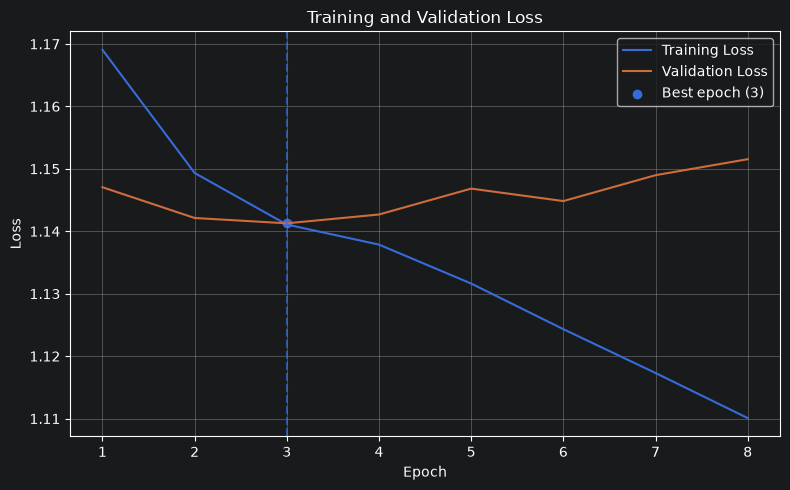

In [20]:
epochs = range(1, len(train_losses) + 1)

best_epoch = val_losses.index(min(val_losses)) + 1
best_val_loss = min(val_losses)

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.scatter(
    best_epoch,
    best_val_loss,
    label=f"Best epoch ({best_epoch})"
)

plt.axvline(
    x=best_epoch,
    linestyle="--",
    alpha=0.7
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "mlp_training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

---

Evaluacija modela. <br>
Sada primenjujemo sigmoidnu funkciju kako bismo dobili verovatnoce pripadnosti pozitivnoj klasi za svaki uzorak.

In [21]:
def predict_probabilities(model, data_loader, device):
    model.eval()

    y_true = []
    y_prob = []

    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)

            logits = model(X_batch)
            probabilities = torch.sigmoid(logits)

            y_true.extend(y_batch.numpy().flatten())
            y_prob.extend(probabilities.cpu().numpy().flatten())

    return np.array(y_true), np.array(y_prob)

In [22]:
y_val_true, y_val_prob = predict_probabilities(
    model=model,
    data_loader=val_loader,
    device=device
)

In [23]:
BASELINE_THRESHOLD = 0.5

y_val_pred = (
    y_val_prob >= BASELINE_THRESHOLD
).astype(int)

Evaluacione metrike na validacionom skupu.

In [24]:
baseline_mlp_validation_results = pd.DataFrame([{
    "model": "Baseline MLP",
    "threshold": BASELINE_THRESHOLD,
    "accuracy": accuracy_score(y_val_true, y_val_pred),
    "precision": precision_score(
        y_val_true,
        y_val_pred,
        zero_division=0
    ),
    "recall": recall_score(
        y_val_true,
        y_val_pred,
        zero_division=0
    ),
    "f1": f1_score(
        y_val_true,
        y_val_pred,
        zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_val_true,
        y_val_prob
    )
}])

baseline_mlp_validation_results.round(4)

,model,threshold,accuracy,precision,recall,f1,roc_auc
0,Baseline MLP,0.5,0.6554,0.1841,0.5904,0.2807,0.6756


In [25]:
baseline_mlp_validation_results.to_csv(
    TABLES_DIR / "baseline_mlp_validation_results.csv",
    index=False
)

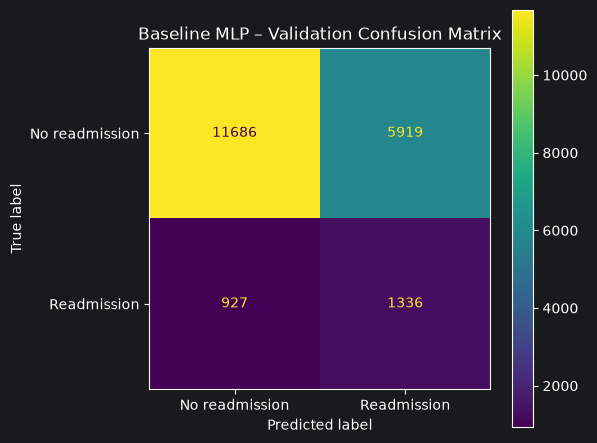

In [26]:
cm = confusion_matrix(y_val_true, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No readmission", "Readmission"]
)

fig, ax = plt.subplots(figsize=(6, 5))

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title("Baseline MLP – Validation Confusion Matrix")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_mlp_validation_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


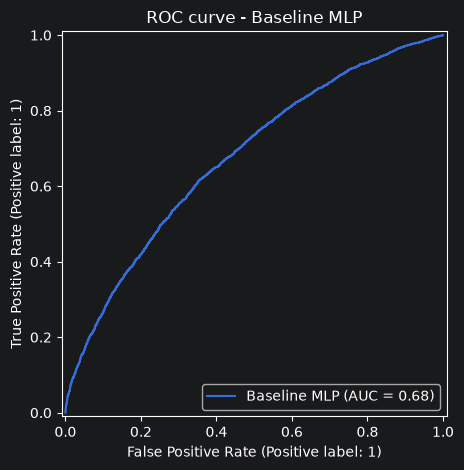

In [27]:
RocCurveDisplay.from_predictions(
    y_val_true,
    y_val_prob,
    name="Baseline MLP"
)

plt.title("ROC curve - Baseline MLP")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_mlp_validation_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()